In [139]:
# Importing the pandas file to work on tabulated data
import pandas as pd

# Reading the phishing_features.csv as df
df = pd.read_csv('/kaggle/input/datasets/victusadi/phishing-urls-dataset-with-extracted-features/phishing_features.csv')

In [140]:
# Read the first 'n' rows of the dataset
# Input format = df.head(n)
df.head(10)

,url,label,url_length,num_dots,has_https,has_ip,num_subdirs,num_params,suspicious_words,tld,special_char_count,digits_count,entropy
0,http://forum.uk.securebankinggroup.com/107519/...,1,89,3,0,0,5,0,2,com,4,29,4.792985
1,http://b45042.com/fish/29,1,25,1,0,0,4,0,0,com,0,7,4.003856
2,http://bet73018.com/lottery/99,1,30,1,0,0,4,0,0,com,0,7,4.053236
3,https://logiin--metsa-autho.webflow.io/,1,39,2,1,0,3,0,0,io,3,0,4.150411
4,https://mettamasklogiiann.webflow.io/,1,37,2,1,0,3,0,0,io,0,0,4.100817
5,http://bet73018.com/lottery/134,1,31,1,0,0,4,0,0,com,0,8,4.063563
6,https://metamasklogenies.webflow.io/,1,36,2,1,0,3,0,0,io,0,0,4.086049
7,https://mmettamaskilogin.webflow.io/,1,36,2,1,0,3,0,1,io,0,0,4.086049
8,https://www.robiox.com.py/users/322503287968/p...,1,52,3,1,0,5,0,0,py,0,12,4.582383
9,https://xbancobhd2025xxxxxxxxx.xo.je/,1,37,2,1,0,3,0,0,je,0,4,3.728139


In [141]:
# Reading the column names of the dataset
df.columns.tolist()

['url',
 'label',
 'url_length',
 'num_dots',
 'has_https',
 'has_ip',
 'num_subdirs',
 'num_params',
 'suspicious_words',
 'tld',
 'special_char_count',
 'digits_count',
 'entropy']

In [142]:
# Reading the number of rows and columns in the dataset
df.shape
# Output format = (Rows, Columns)

(160064, 13)

In [143]:
# Reading the data types of the columns in the dataset
df.dtypes

url                    object
label                   int64
url_length              int64
num_dots                int64
has_https               int64
has_ip                  int64
num_subdirs             int64
num_params              int64
suspicious_words        int64
tld                    object
special_char_count      int64
digits_count            int64
entropy               float64
dtype: object

In [144]:
# Counting the number of non-null data and reading data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160064 entries, 0 to 160063
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   url                 160064 non-null  object 
 1   label               160064 non-null  int64  
 2   url_length          160064 non-null  int64  
 3   num_dots            160064 non-null  int64  
 4   has_https           160064 non-null  int64  
 5   has_ip              160064 non-null  int64  
 6   num_subdirs         160064 non-null  int64  
 7   num_params          160064 non-null  int64  
 8   suspicious_words    160064 non-null  int64  
 9   tld                 159243 non-null  object 
 10  special_char_count  160064 non-null  int64  
 11  digits_count        160064 non-null  int64  
 12  entropy             160064 non-null  float64
dtypes: float64(1), int64(10), object(2)
memory usage: 15.9+ MB


In [145]:
# Finding count of missing values
mv_count = df.isnull().sum()
print(mv_count)

url                     0
label                   0
url_length              0
num_dots                0
has_https               0
has_ip                  0
num_subdirs             0
num_params              0
suspicious_words        0
tld                   821
special_char_count      0
digits_count            0
entropy                 0
dtype: int64


In [146]:
# Finding total number of missing cells
missing_values_cells = mv_count.sum()

print(missing_values_cells)

821


In [147]:
# Finding missing values % rounded off to 2 decimals
mv_percentage = (df.isnull().mean() * 100).round(2)
print(mv_percentage)

url                   0.00
label                 0.00
url_length            0.00
num_dots              0.00
has_https             0.00
has_ip                0.00
num_subdirs           0.00
num_params            0.00
suspicious_words      0.00
tld                   0.51
special_char_count    0.00
digits_count          0.00
entropy               0.00
dtype: float64


In [148]:
# Creating a report of missing values
# pd.DataFrame() is used to create a data frame or a table of labelled rows & columns
mv_report = pd.DataFrame({
    "Count of Missing Values": mv_count,
    "Missing Values %": mv_percentage
})

print(mv_report)

                    Count of Missing Values  Missing Values %
url                                       0              0.00
label                                     0              0.00
url_length                                0              0.00
num_dots                                  0              0.00
has_https                                 0              0.00
has_ip                                    0              0.00
num_subdirs                               0              0.00
num_params                                0              0.00
suspicious_words                          0              0.00
tld                                     821              0.51
special_char_count                        0              0.00
digits_count                              0              0.00
entropy                                   0              0.00


In [149]:
# Sorting the missing values report
# {dataframe_name}.sort_values(by = "{column_name}", ascending = {True/False}) is used to sort a dataframe/table
sorted_mv_report = mv_report.sort_values(by = "Count of Missing Values", ascending = False)

print(sorted_mv_report)

                    Count of Missing Values  Missing Values %
tld                                     821              0.51
label                                     0              0.00
url_length                                0              0.00
num_dots                                  0              0.00
url                                       0              0.00
has_https                                 0              0.00
has_ip                                    0              0.00
num_params                                0              0.00
num_subdirs                               0              0.00
suspicious_words                          0              0.00
special_char_count                        0              0.00
digits_count                              0              0.00
entropy                                   0              0.00


In [150]:
# Printing non-null positive values from the sorted missing values report
print(sorted_mv_report[sorted_mv_report["Count of Missing Values"] > 0])

     Count of Missing Values  Missing Values %
tld                      821              0.51


In [151]:
# Inspecting labels and class distribution of the target column 
target_column = "label"

# Finding unique labels in the target column
unique_labels = df[target_column].unique()

print(unique_labels)

[1 0]


In [152]:
# Finding how many times the unique value appears in the target column
uv_count = df[target_column].value_counts()

print(uv_count)

label
1    159244
0       820
Name: count, dtype: int64


In [153]:
# Finding the unique value appearance % in the target column
uv_percentage = df[target_column].value_counts(normalize = True).mul(100).round(2)

print(uv_percentage)

label
1    99.49
0     0.51
Name: proportion, dtype: float64


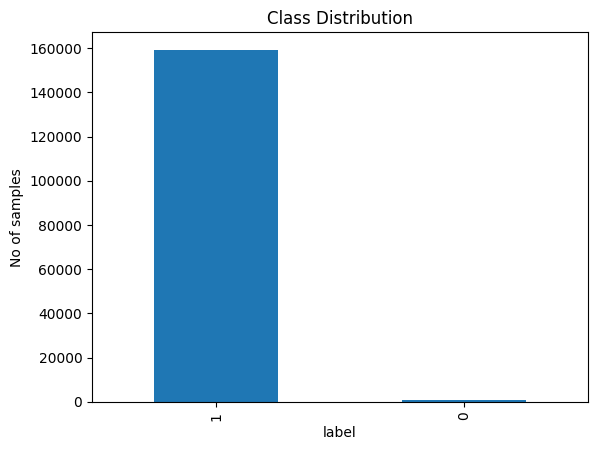

In [154]:
# Importing matplotlib to generate graphs
import matplotlib.pyplot as plt

# Representing the target columns as a bar graph
uv_count.plot(kind = "bar")

# Give the bar graph the title 'Class Distribution'
plt.title("Class Distribution")

# Give the x-axis the target column as label
plt.xlabel(target_column)

# Give the y-axis the label 'No. of samples'
plt.ylabel("No of samples")

# Output = Bar graph
plt.show()

In [155]:
# Importing the train_test_split function from the model_selection library of sklearn to randomly distribute the dataset into a training set and a test set
from sklearn.model_selection import train_test_split

# Take x as all the columns except the target column
x = df.drop(columns = [target_column])

# Take y as target column values
y = df[target_column]

# Splitting the dataset into 80% training set and 20% testing set
x1_train, x1_test, y1_train, y1_test = train_test_split(
    x, y, test_size = 0.20, random_state = 42, stratify = y
)
# random_state = 42 prevents the model from generating a different train and test model everytime the model is run
# stratify = y tells the model to preserve the same class proportions in both the training and testing sets

In [156]:
# Printing the number of rows and colums in the training set data
print("Training set:", x1_train.shape, y1_train.shape)

Training set: (128051, 12) (128051,)


In [157]:
# Printing the number of rows & columns in the testing set data
print("Testing set:", x1_test.shape, y1_test.shape)

Testing set: (32013, 12) (32013,)


In [158]:
# Finding the percentage of unique values in the target column in the training set
training_uv_percentage = y1_train.value_counts(normalize = True).mul(100).round(2)

print(training_uv_percentage)

label
1    99.49
0     0.51
Name: proportion, dtype: float64


In [159]:
# Finding the percentage of unique values in the target column in the testing set
testing_uv_percentage = y1_test.value_counts(normalize = True).mul(100).round(2)

print(testing_uv_percentage)

label
1    99.49
0     0.51
Name: proportion, dtype: float64


In [160]:
# url is a text feature, so we use its numerical engineered features
numerical_feature_columns = [
    "url_length", "num_dots", "has_https", "has_ip", "num_subdirs", "num_params", "suspicious_words", "special_char_count", "digits_count", "entropy"
]

# Take x as the values of all numeric engineered columns
x = df[numerical_feature_columns]

# Take y as target column values
y = df[target_column]

#Splitting the dataset into 80% training set and 20% testing set for the new x & y values
x2_train, x2_test, y2_train, y2_test = train_test_split(
    x, y, test_size = 0.20, random_state = 42, stratify = y
)